In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping


In [36]:
model = Sequential([
    Dense(32, activation='relu', input_shape=(1,)),
    Dense(64, activation='relu'),
    Dense(128, activation='relu'),
    Dense(1)
])

model.summary()

/run/media/biologist/Captain America/All Semester/4.1/corefx/AI/.venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,625 (41.50 KB)

 Trainable params: 10,625 (41.50 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
def poly(x):
    return x**3 - 2*x**2 + 5*x + 1

In [38]:
x = np.linspace(-20, 20, 1000)
y = poly(x)

x_norm = x / 20

y_max = np.max(np.abs(y))
y_norm = y / y_max

df = pd.DataFrame({
    "Original x: " : x,
    "Normalized x: " : x_norm,
    "Original y: " : y,
    "Normalized y " : y_norm
})

df.head(10)

,Original x:,Normalized x:,Original y:,Normalized y
0,-20.00000,-1.000000,-8899.000000,-1.000000
1,-19.95996,-0.997998,-8847.647883,-0.994229
2,-19.91992,-0.995996,-8796.494178,-0.988481
3,-19.87988,-0.993994,-8745.538501,-0.982755
4,-19.83984,-0.991992,-8694.780465,-0.977051
5,-19.79980,-0.989990,-8644.219686,-0.971370
6,-19.75976,-0.987988,-8593.855779,-0.965710
7,-19.71972,-0.985986,-8543.688358,-0.960073
8,-19.67968,-0.983984,-8493.717039,-0.954457
9,-19.63964,-0.981982,-8443.941435,-0.948864


In [65]:
X_train, X_test, y_train, y_test = train_test_split(
    x_norm, y_norm,
    test_size = 0.1,
    random_state = 42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size = 0.1111,
    random_state = 42
)


model.compile(
    optimizer = 'adam',
    loss = 'mse',
    metrics = ['mae']
)

early_stop = EarlyStopping(
    monitor = 'val_loss',
    patience = 5,
    restore_best_weights = True,
    verbose = 1
)

history = model.fit(
    X_train, y_train,
    validation_data = (X_val, y_val),
    epochs = 100,
    batch_size = 32,
    callbacks = [early_stop]
)


Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0011 - mae: 0.0236 - val_loss: 1.1998e-04 - val_mae: 0.0079
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.3217e-04 - mae: 0.0083 - val_loss: 1.0795e-04 - val_mae: 0.0080
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 3.6046e-05 - mae: 0.0041 - val_loss: 1.0469e-05 - val_mae: 0.0023
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 8.7651e-06 - mae: 0.0019 - val_loss: 6.7790e-06 - val_mae: 0.0018
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 4.9751e-06 - mae: 0.0014 - val_loss: 4.5399e-06 - val_mae: 0.0014
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 4.0407e-06 - mae: 0.0012 - val_loss: 3.9892e-06 - val_mae: 0.0014
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 3.7235e-06 - mae: 0.0012 - val_loss: 4.4212e-06 - val_mae: 0.0016
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 3.3666e-06 - mae: 0.0011 - val_loss: 4.5744e-06 - val_mae: 0.0017
Epo

In [73]:
y_pred = model.predict(X_test)
print()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step



In [67]:
loss, mae = model.evaluate(X_test, y_test)

print("Loss : ", loss)
print("MAE : ", mae)

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 1.2494e-06 - mae: 9.4346e-04

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 2.7073e-06 - mae: 0.0011    
Loss :  2.707318344619125e-06
MAE :  0.0011067235609516501


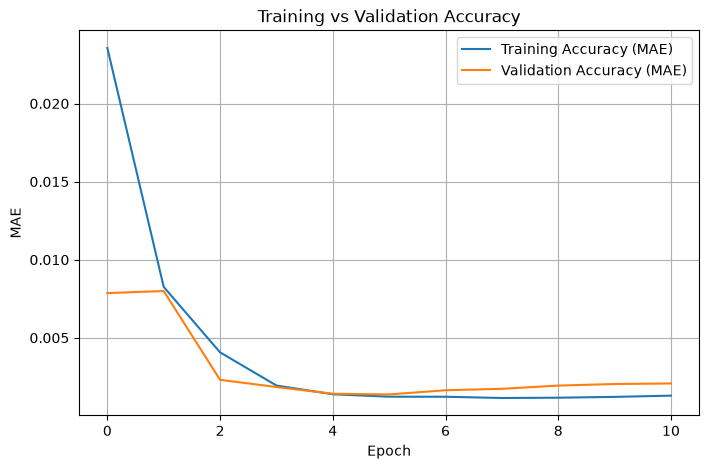

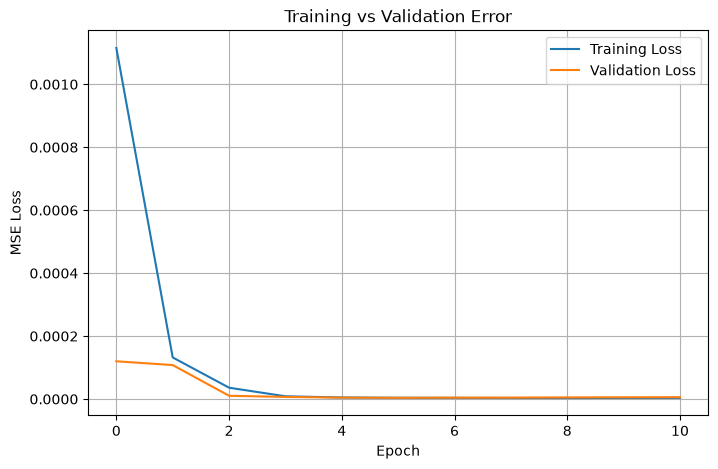

In [68]:
plt.figure(figsize=(8,5))
plt.plot(history.history['mae'], label='Training Accuracy (MAE)')
plt.plot(history.history['val_mae'], label='Validation Accuracy (MAE)')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training vs Validation Error')
plt.legend()
plt.grid(True)
plt.show()